**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
By: TAP

In [1]:
%pip install numpy matplotlib tensorflow

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/35

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mediapipe 0.10.21 requires protobuf<5,>=4.25.3, but you have protobuf 7.36.2 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 16us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 183s 7us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 14s 3us/step


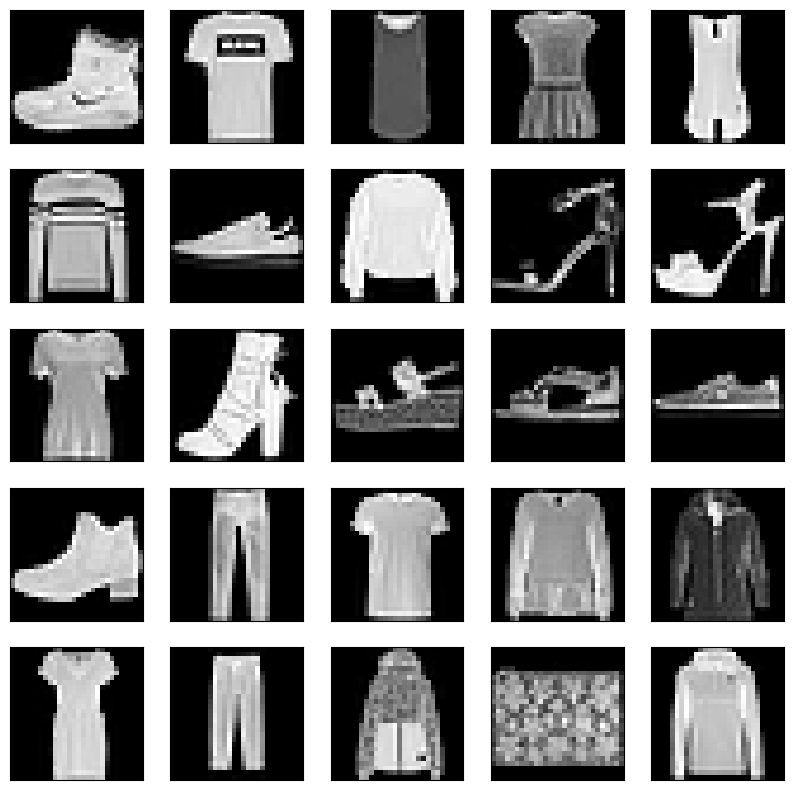

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt

# Load dataset Fashion MNIST
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Normalize nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Melihat contoh gambar
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
plt.show()


In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Flatten(input_shape=(28, 28)),  # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),  # Hidden layer dengan 128 neuron
    Dense(10, activation='softmax')  # Output layer dengan 10 neuron untuk klasifikasi 10 kategori
])

# Melihat ringkasan arsitektur model
model.summary()


c:\Users\Asus\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8252 - loss: 0.4986 - val_accuracy: 0.8425 - val_loss: 0.4378
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8649 - loss: 0.3757 - val_accuracy: 0.8650 - val_loss: 0.3760
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8763 - loss: 0.3376 - val_accuracy: 0.8601 - val_loss: 0.3872
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8855 - loss: 0.3118 - val_accuracy: 0.8713 - val_loss: 0.3589
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8902 - loss: 0.2958 - val_accuracy: 0.8758 - val_loss: 0.3398
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8959 - loss: 0.2801 - val_accuracy: 0.8770 - val_loss: 0.3439
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9006 - loss: 0.2683 - val_accuracy: 0.8849 - val_loss: 0.3309
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9040 - loss: 0.2579 - 

In [4]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest accuracy: {test_acc}')


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8852 - loss: 0.3237

Test accuracy: 0.885200023651123


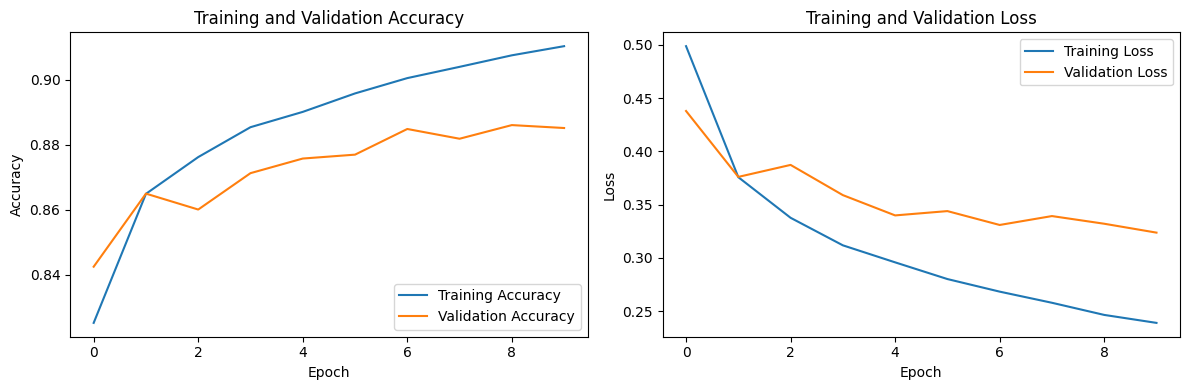

In [5]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


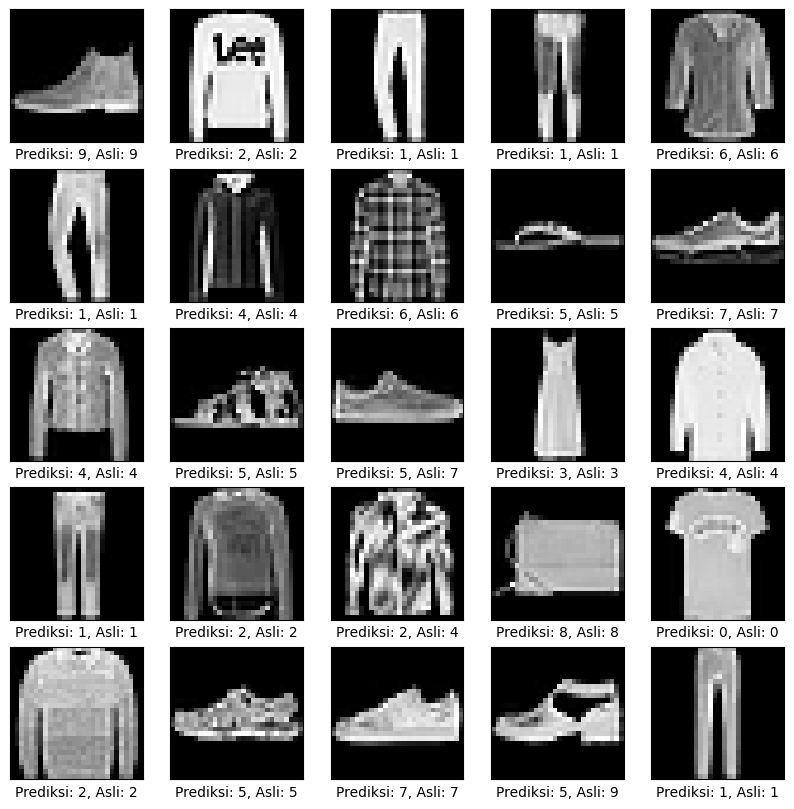

In [6]:
# Melakukan prediksi pada gambar pengujian
import numpy as np
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}")
plt.show()


**Penjelasan** <br>
Pada praktikum ini, kita telah membuat model Artificial Neural Network (ANN) menggunakan TensorFlow dan Keras dengan dataset Fashion-MNIST untuk mengklasifikasikan gambar pakaian ke dalam 10 kategori. Tahap pertama adalah mengimpor library yang dibutuhkan, seperti TensorFlow, NumPy, Matplotlib, dan Fashion-MNIST, kemudian memuat dataset yang terdiri dari data training dan testing. Selanjutnya, kita membangun arsitektur Neural Network menggunakan Sequential yang terdiri dari layer Flatten untuk mengubah gambar berukuran 28 × 28 piksel menjadi vektor 784 nilai, hidden layer dengan 128 neuron menggunakan fungsi aktivasi ReLU, serta output layer dengan 10 neuron menggunakan Softmax untuk menghasilkan probabilitas setiap kategori. Setelah arsitektur dibuat, model dikompilasi menggunakan optimizer Adam, loss function Sparse Categorical Crossentropy, dan metrik Accuracy, kemudian dilatih menggunakan data training selama 10 epoch. Setelah proses training selesai, model dievaluasi menggunakan data testing untuk mengetahui nilai akurasi (test_acc) dan kesalahan prediksi (test_loss). Kita juga membuat visualisasi grafik Training Accuracy, Validation Accuracy, Training Loss, dan Validation Loss untuk melihat perkembangan proses pembelajaran model serta mengetahui kemungkinan terjadinya overfitting. Terakhir, kita melakukan prediksi terhadap 25 gambar pertama pada data pengujian menggunakan model.predict() dan membandingkan hasil prediksi dengan label sebenarnya. Dengan demikian, praktikum ini menghasilkan sebuah model Neural Network yang mampu mempelajari pola gambar dan melakukan klasifikasi otomatis terhadap 10 kategori pakaian pada dataset Fashion-MNIST.